## Baseline training script

### Imports

In [1]:
import sys
from pathlib import Path

project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import lightning.pytorch as pl
import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data import CLASS_NAMES, BloodDataModule

print(f"PyTorch:   {torch.__version__}")
print(f"Lightning: {pl.__version__}")
print(f"CUDA:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device:    {torch.cuda.get_device_name(0)}")

PyTorch:   2.14.1+cu126
Lightning: 2.6.6
CUDA:      True
Device:    NVIDIA GeForce RTX 3050 Laptop GPU


### Data initialisation

In [2]:
dm = BloodDataModule(batch_size=64, use_augmentations=True, grayscale=False, num_workers=0)
dm.setup()

print(f"Train samples: {len(dm.train_dataset):,}")
print(f"Val samples:   {len(dm.val_dataset):,}")
print(f"Test samples:  {len(dm.test_dataset):,}")
print(f"Channels:      {dm.in_channels}")
print(f"Train mean:    {np.round(dm.train_mean, 4)}")
print(f"Train std:     {np.round(dm.train_std, 4)}")

print("\nClass counts and weights (train):")
counts = dm.class_counts.numpy()
weights = dm.class_weights.numpy()
for idx, (name, c, w) in enumerate(zip(CLASS_NAMES, counts, weights)):
    print(f"  [{idx}] {name:<20}: count={c:5d} ({c / len(dm.train_dataset) * 100:5.2f}%), weight={w:.4f}")

Train samples: 11,959
Val samples:   1,712
Test samples:  3,421
Channels:      3
Train mean:    [0.8162 0.6685 0.6955]
Train std:     [0.2152 0.2415 0.1175]

Class counts and weights (train):
  [0] Basophil            : count=  852 ( 7.12%), weight=1.4975
  [1] Eosinophil          : count= 2181 (18.24%), weight=0.5850
  [2] Erythroblast        : count= 1085 ( 9.07%), weight=1.1759
  [3] Immature Granulocyte: count= 2026 (16.94%), weight=0.6298
  [4] Lymphocyte          : count=  849 ( 7.10%), weight=1.5028
  [5] Monocyte            : count=  993 ( 8.30%), weight=1.2849
  [6] Neutrophil          : count= 2330 (19.48%), weight=0.5476
  [7] Platelet            : count= 1643 (13.74%), weight=0.7766


In [3]:
batch_x, batch_y = next(iter(dm.train_dataloader()))

print(f"batch_x: shape={batch_x.shape}, dtype={batch_x.dtype}, range=[{batch_x.min():.2f}, {batch_x.max():.2f}]")
print(f"batch_y: shape={batch_y.shape}, dtype={batch_y.dtype}")
print(f"labels:  {batch_y[:10].tolist()}")

batch_x: shape=torch.Size([64, 3, 28, 28]), dtype=torch.float32, range=[-5.92, 2.59]
batch_y: shape=torch.Size([64]), dtype=torch.int64
labels:  [3, 7, 6, 1, 1, 7, 2, 6, 0, 6]


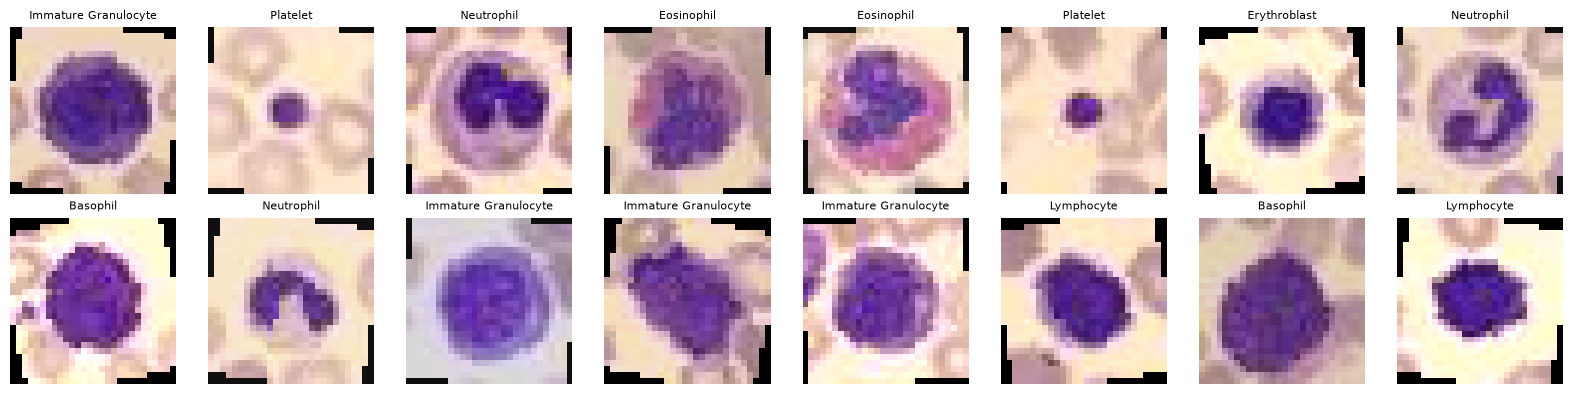

In [4]:
def denormalize(tensor, mean, std):
    img = tensor.clone().detach().cpu()
    mean_t = torch.tensor(mean).view(-1, 1, 1)
    std_t = torch.tensor(std).view(-1, 1, 1)
    img = img * std_t + mean_t
    return torch.clamp(img, 0.0, 1.0).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flatten()):
    img = denormalize(batch_x[i], dm.train_mean, dm.train_std)
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[batch_y[i]], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()